In [11]:
import pandas as pd
import seaborn as sns
import numpy as np

In [10]:
df = pd.read_parquet('./data/ff_market_daily.parquet')
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date').reset_index(drop=True)

print(f"{len(df):,} trading-day observations: "
      f"{df['date'].min():%Y-%m-%d} to {df['date'].max():%Y-%m-%d}")
print(f"Are dates ordered? {df['date'].is_monotonic_increasing}")
df[['date', 'market_return_pct']].head()

26,296 trading-day observations: 1926-07-01 to 2026-07-31
Are dates ordered? True


,date,market_return_pct
0,1926-07-01,0.10
1,1926-07-02,0.46
2,1926-07-06,0.18
3,1926-07-07,0.10
4,1926-07-08,0.23


<Axes: xlabel='market_return_pct', ylabel='Density'>

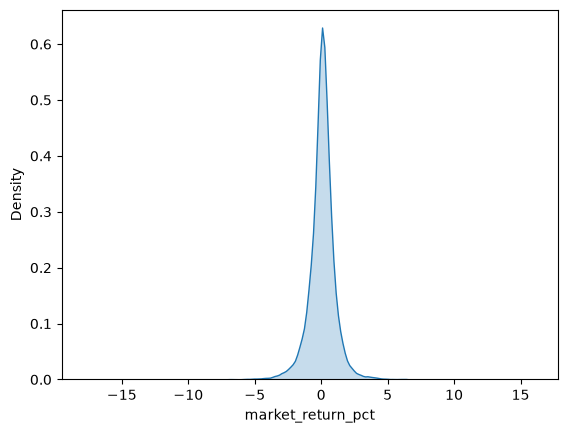

In [6]:
sns.kdeplot(df['market_return_pct'], fill=True)

<Axes: xlabel='date', ylabel='market_return_pct'>

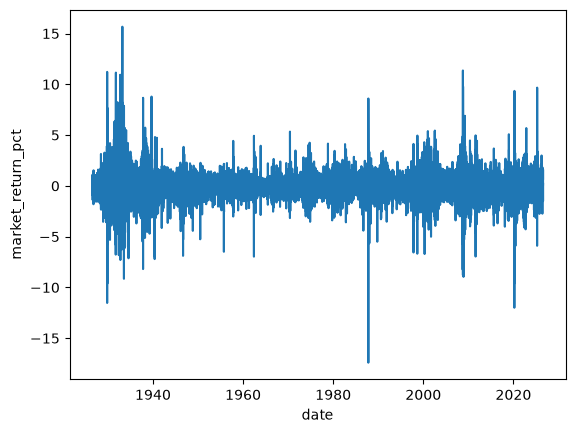

In [8]:
sns.lineplot(x=df['date'], y=df['market_return_pct'])

In [13]:
df['y_t'] = np.where(df['market_return_pct'] < 0, 'Loss', 'Gain')
df['y_tp1'] = df['y_t'].shift(-1)  # next day's state
pd.crosstab(df['y_t'], df['y_tp1'])


y_tp1,Gain,Loss
y_t,,
Gain,8593,5967
Loss,5967,5768


<Axes: xlabel='y_tp1', ylabel='y_t'>

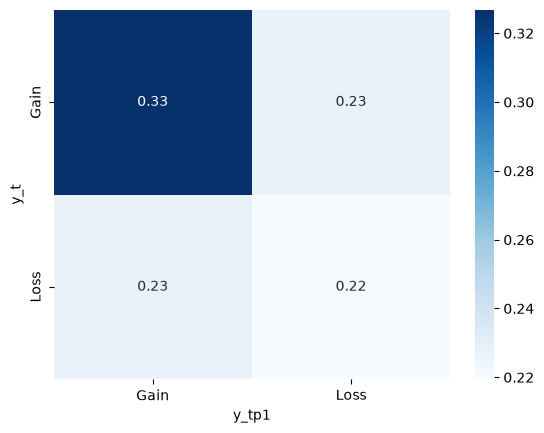

In [14]:
tab = pd.crosstab(df['y_t'], df['y_tp1'], normalize=True)
tab


sns.heatmap(tab, annot=True, fmt='.2f', cmap='Blues')

In [15]:
tab = pd.crosstab(df['y_t'], df['y_tp1'], 
            normalize = True, margins = True)
tab

y_tp1,Gain,Loss,All
y_t,,,
Gain,0.326792,0.226925,0.553717
Loss,0.226925,0.219357,0.446283
All,0.553717,0.446283,1.000000


<Axes: xlabel='y_tp1', ylabel='y_t'>

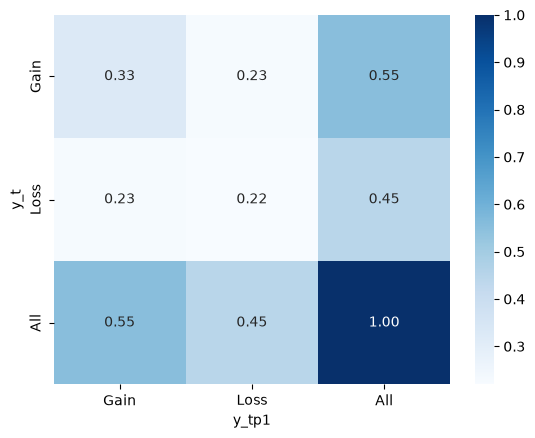

In [16]:
sns.heatmap(tab, annot=True, fmt='.2f', cmap='Blues')

Conditional

In [17]:
tab = pd.crosstab(df['y_t'], df['y_tp1'], 
            normalize = 'index')
tab

y_tp1,Gain,Loss
y_t,,
Gain,0.590179,0.409821
Loss,0.508479,0.491521


<Axes: xlabel='y_tp1', ylabel='y_t'>

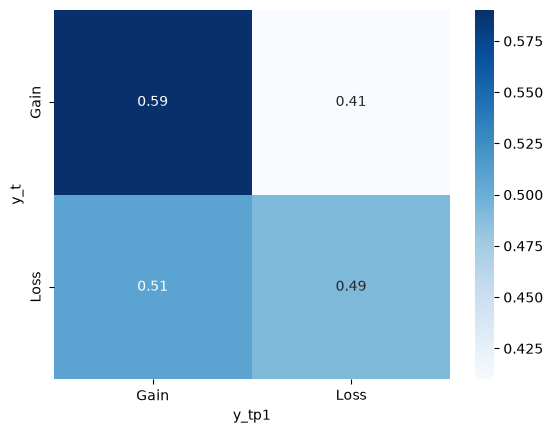

In [18]:
sns.heatmap(tab, annot=True, fmt='.2f', cmap='Blues')